# Digital Filter Design and Quantitative Validation

## Objective
Evaluate digital filters using a synthetic signal containing known useful components and unwanted interference.

## Experiments
1. Generate a signal with known frequency components.
2. Design a 20 Hz notch filter.
3. Design a Butterworth low-pass filter.
4. Compare frequency responses and power spectra.
5. Quantify attenuation and examine waveform changes.
6. Document limitations and reproducibility.

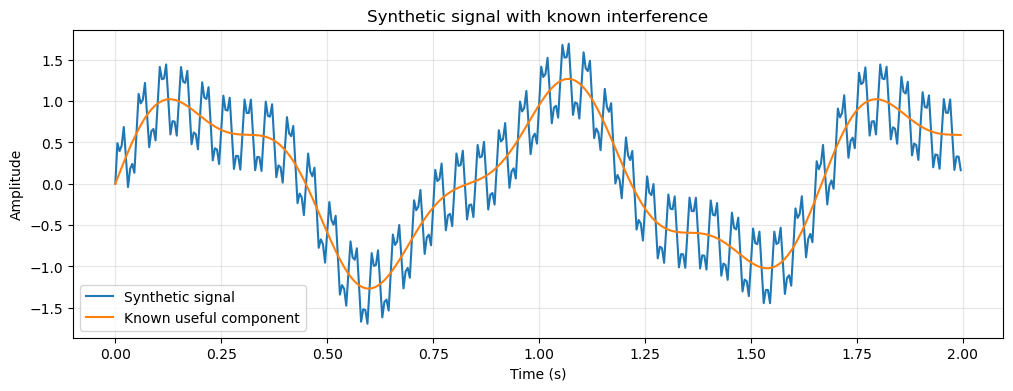

Sampling frequency: 200 Hz
Number of samples: 2000
Duration: 10.0 seconds


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, iirnotch, filtfilt, butter, sosfiltfilt

FS = 200
DURATION = 10
t = np.arange(0, DURATION, 1/FS)

# Known useful components plus unwanted interference
useful = (
    1.0 * np.sin(2 * np.pi * 1.2 * t)
    + 0.3 * np.sin(2 * np.pi * 3.0 * t)
)

interference = (
    0.4 * np.sin(2 * np.pi * 20 * t)
    + 0.2 * np.sin(2 * np.pi * 60 * t)
)

x = useful + interference

plt.figure(figsize=(12, 4))
plt.plot(t[:400], x[:400], label="Synthetic signal")
plt.plot(t[:400], useful[:400], label="Known useful component")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Synthetic signal with known interference")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("Sampling frequency:", FS, "Hz")
print("Number of samples:", len(x))
print("Duration:", len(x)/FS, "seconds")

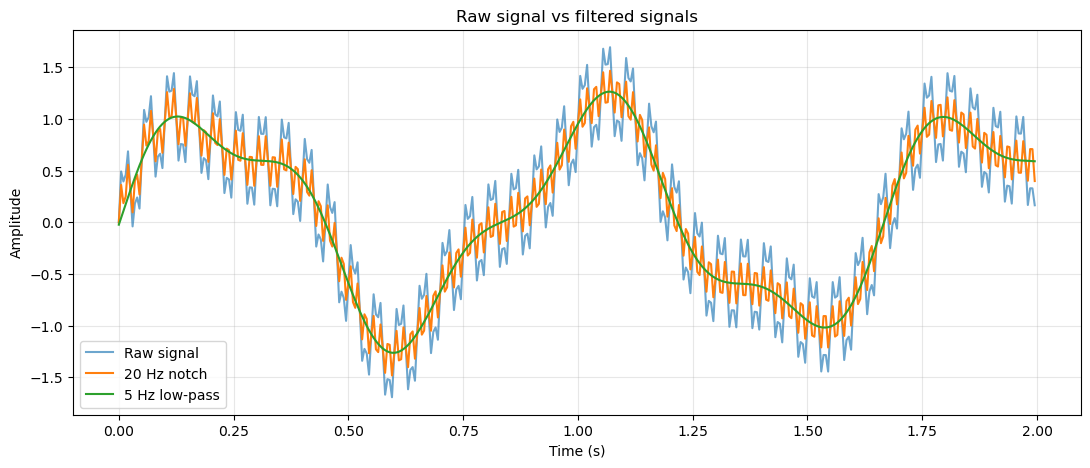

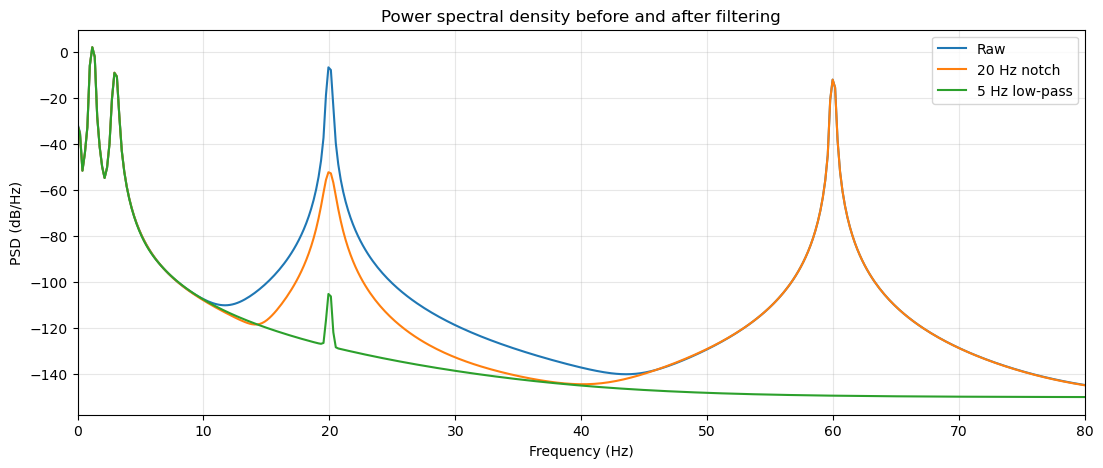

In [2]:
from scipy.signal import (
    iirnotch, butter, filtfilt, sosfiltfilt,
    welch, freqz
)

# 1. Design filters
b_notch, a_notch = iirnotch(w0=20, Q=25, fs=FS)
x_notch = filtfilt(b_notch, a_notch, x)

sos_lowpass = butter(
    N=4, Wn=5, btype="lowpass", fs=FS, output="sos"
)
x_lowpass = sosfiltfilt(sos_lowpass, x)

# 2. Compare waveforms
plt.figure(figsize=(13, 5))
plt.plot(t[:400], x[:400], label="Raw signal", alpha=0.65)
plt.plot(t[:400], x_notch[:400], label="20 Hz notch")
plt.plot(t[:400], x_lowpass[:400], label="5 Hz low-pass")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Raw signal vs filtered signals")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Compare power spectral density
plt.figure(figsize=(13, 5))

for signal, label in [
    (x, "Raw"),
    (x_notch, "20 Hz notch"),
    (x_lowpass, "5 Hz low-pass")
]:
    f, pxx = welch(signal, fs=FS, nperseg=1024)
    plt.plot(f, 10*np.log10(pxx + 1e-15), label=label)

plt.xlim(0, 80)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Power spectral density before and after filtering")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [4]:
import pandas as pd
from scipy.optimize import least_squares

def sinusoid_amplitude(signal, frequency, fs):
    time = np.arange(len(signal)) / fs
    A = np.column_stack([
        np.sin(2*np.pi*frequency*time),
        np.cos(2*np.pi*frequency*time),
        np.ones(len(time))
    ])
    coeff, *_ = np.linalg.lstsq(A, signal, rcond=None)
    return np.hypot(coeff[0], coeff[1])

def attenuation_db(before, after, frequency, fs):
    amp_before = sinusoid_amplitude(before, frequency, fs)
    amp_after = sinusoid_amplitude(after, frequency, fs)
    return 20*np.log10(
        max(amp_before, 1e-15) / max(amp_after, 1e-15)
    )

signals_to_test = {
    "Raw": x,
    "20 Hz notch": x_notch,
    "5 Hz low-pass": x_lowpass
}

# Frequency-specific amplitude and attenuation
rows = []
for name, signal in signals_to_test.items():
    rows.append({
        "Signal": name,
        "20 Hz amplitude": sinusoid_amplitude(signal, 20, FS),
        "60 Hz amplitude": sinusoid_amplitude(signal, 60, FS),
        "RMSE vs useful": np.sqrt(np.mean((signal-useful)**2)),
        "Correlation vs useful": np.corrcoef(signal, useful)[0, 1]
    })

results = pd.DataFrame(rows)
display(results.round(4))

print("Attenuation relative to raw:")
for name, signal in signals_to_test.items():
    if name == "Raw":
        continue
    print(
        f"{name}: "
        f"20 Hz = {attenuation_db(x, signal, 20, FS):.2f} dB, "
        f"60 Hz = {attenuation_db(x, signal, 60, FS):.2f} dB"
    )

,Signal,20 Hz amplitude,60 Hz amplitude,RMSE vs useful,Correlation vs useful
0,Raw,0.4000,0.2000,0.3162,0.9192
1,20 Hz notch,0.0094,0.2000,0.1427,0.9818
2,5 Hz low-pass,0.0007,0.0003,0.0195,0.9997


Attenuation relative to raw:
20 Hz notch: 20 Hz = 32.62 dB, 60 Hz = 0.00 dB
5 Hz low-pass: 20 Hz = 54.62 dB, 60 Hz = 57.10 dB


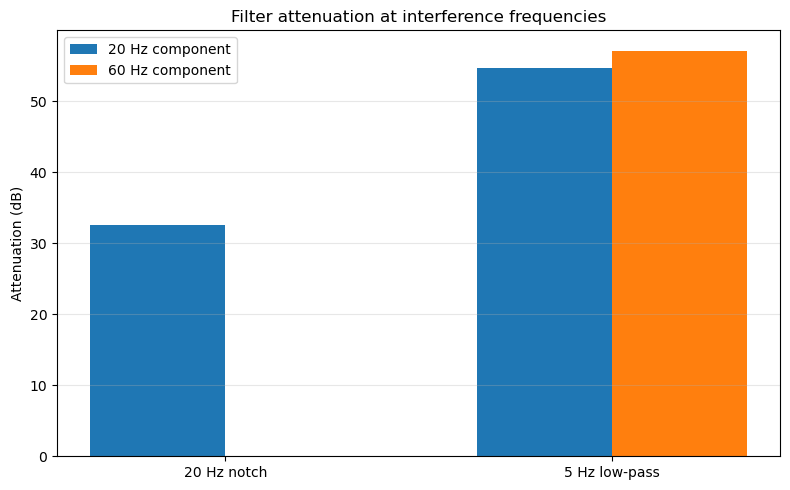

In [5]:
import matplotlib.pyplot as plt
import numpy as np

filter_names = ["20 Hz notch", "5 Hz low-pass"]
attenuation_20 = [32.62, 54.62]
attenuation_60 = [0.00, 57.10]

xpos = np.arange(len(filter_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(xpos - width/2, attenuation_20, width,
       label="20 Hz component")
ax.bar(xpos + width/2, attenuation_60, width,
       label="60 Hz component")

ax.set_xticks(xpos)
ax.set_xticklabels(filter_names)
ax.set_ylabel("Attenuation (dB)")
ax.set_title("Filter attenuation at interference frequencies")
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("../outputs/plots/filter_attenuation.png",
            dpi=200, bbox_inches="tight")
plt.show()

## Quantitative Filter Validation — Results

A synthetic signal containing useful 1.2 Hz and 3 Hz components was combined with 20 Hz and 60 Hz interference. A second-order IIR notch filter with a centre frequency of 20 Hz and Q = 25 was compared with a fourth-order Butterworth low-pass filter with a 5 Hz cutoff. Both were applied using forward-backward filtering.

The notch filter attenuated the 20 Hz component by 32.62 dB while leaving the 60 Hz component essentially unchanged. Its RMSE relative to the known useful signal decreased from 0.3162 to 0.1427.

The low-pass filter attenuated the 20 Hz and 60 Hz components by 54.62 dB and 57.10 dB, respectively. Its RMSE was 0.0195, with a correlation of 0.9997 against the known useful signal.

For this synthetic example, the low-pass filter produced the lowest reconstruction error because the defined useful signal components lie below 5 Hz. This result does not establish that the same cutoff is appropriate for real PPG signals or other measurement systems.

The experiment demonstrates the importance of selecting filters according to the useful signal bandwidth, validating their effects quantitatively, and avoiding conclusions based on visual smoothness alone.